# E9b: cortes operativos por patrón, con regla de episodio

Reglas fijadas antes en `README.md` (E9b): como máximo una intervención por patrón cada 60 min y 10 min de enfriamiento entre intervenciones; piso de precisión de 50 % por patrón; techo de 6 intervenciones por día y patrón (12 en total). Para cada modelo, *c* es el menor corte que cumple las dos condiciones; si ninguno llega al piso, el de mayor precisión.

In [1]:
import os, json
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from experiments import e9b as E
from pipelines.labels.build_windows import seconds

SEEDS = range(5)
d8 = pd.read_parquet("data/reports/e8d_scores.parquet")
bS = pd.read_parquet("data/reports/e4b_scores_b30.parquet")
r0 = pd.read_csv("data/processed/real_features.csv", usecols=["user_id", "t_utc", "day", "y_f", "y_s"])
rS = pd.read_csv("data/processed/real_features_b30.csv", usecols=["user_id", "t_utc", "y_s"])
r0["p_f"] = np.mean([d8[f"y_f|+ all dynamics|{s}"] for s in SEEDS], axis=0)
r0["p_s"] = np.mean([d8[f"y_s|baseline|{s}"] for s in SEEDS], axis=0)
rS["p_sB"] = np.mean([bS[f"y_s|{s}"] for s in SEEDS], axis=0)
df = r0.merge(rS.rename(columns={"y_s": "y_sB"}), on=["user_id", "t_utc"], how="inner")
df["t"] = seconds(pd.to_datetime(df["t_utc"]))
df = df.sort_values(["user_id", "t"]).reset_index(drop=True)
print(f"{len(df)} common decision points ({len(r0)} with b = 0, {len(rS)} with b = 30), "
      f"{df.user_id.nunique()} people, {df.groupby(['user_id', 'day']).ngroups} person-days")

16233 common decision points (16281 with b = 0, 16318 with b = 30), 18 people, 164 person-days


## Barrido de cortes, cada modelo solo

In [2]:
sB = df.assign(p_s=df["p_sB"], y_s=df["y_sB"])   # S with the shifted label in the S slot
models = {"F (b = 0)": (df, "F", "p_f"), "S (b = 0)": (df, "S", "p_s"), "S (b = 30)": (sB, "S", "p_s")}
sweeps, chosen = {}, {}
for name, (frame, pattern, col) in models.items():
    cuts = np.unique(np.quantile(frame[col], np.linspace(0.30, 0.995, 60)))
    sweeps[name] = E.sweep(frame, pattern, cuts)
    chosen[name] = E.choose(sweeps[name])
pick = pd.DataFrame({name: sweeps[name].set_index("c").loc[c].to_dict() | {"c": c, "meets both": ok}
                     for name, (c, ok) in chosen.items()}).T
pick[["c", "meets both", "precision", "episode_sensitivity", "point_coverage", "per_day_mean", "per_day_p90"]].round(3)

,c,meets both,precision,episode_sensitivity,point_coverage,per_day_mean,per_day_p90
F (b = 0),0.345724,True,0.51269,0.238579,0.482093,2.402439,6.0
S (b = 0),0.330727,False,0.397237,0.427646,0.363541,3.530488,7.0
S (b = 30),0.252018,True,0.520041,0.907895,0.871712,5.932927,10.0


## Precisión e intervenciones por día según el corte

Cada medida en su propio eje. Líneas grises: piso de precisión (50 %) y techo por patrón (6 por día). Punto: el corte elegido.

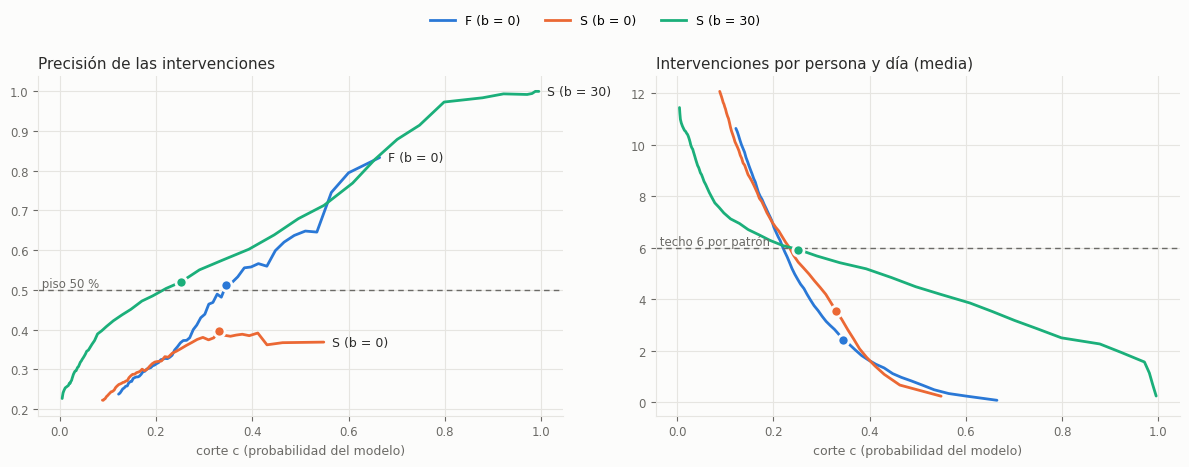

In [3]:
COLORS = {"F (b = 0)": "#2a78d6", "S (b = 0)": "#eb6834", "S (b = 30)": "#1baf7a"}  # validated, light surface
INK, MUTED, GRID = "#2b2b2a", "#6b6a66", "#e6e5e1"
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), facecolor="#fcfcfb")
panels = [("precision", "Precisión de las intervenciones", E.PRECISION_FLOOR, "piso 50 %"),
          ("per_day_mean", "Intervenciones por persona y día (media)", E.PER_PATTERN_MAX_DAY, "techo 6 por patrón")]
for ax, (col, title, ref, ref_label) in zip(axes, panels):
    ax.set_facecolor("#fcfcfb")
    for name, tab in sweeps.items():
        ax.plot(tab["c"], tab[col], color=COLORS[name], lw=2, solid_capstyle="round")
        c, _ = chosen[name]
        y = tab.set_index("c").loc[c, col]
        ax.plot([c], [y], "o", ms=8, color=COLORS[name], mec="#fcfcfb", mew=2, zorder=3)
        last = tab.iloc[-1]
        if col == "precision":  # end labels collide near 0 in the load panel; the legend names the lines
            ax.annotate(name, (last["c"], last[col]), xytext=(6, 0), textcoords="offset points",
                        va="center", fontsize=9, color=INK)
    ax.axhline(ref, color=MUTED, lw=1, ls=(0, (4, 3)))
    ax.text(ax.get_xlim()[0], ref, f" {ref_label}", va="bottom", fontsize=8.5, color=MUTED)
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.set_xlabel("corte c (probabilidad del modelo)", fontsize=9, color=MUTED)
    ax.grid(color=GRID, lw=0.8); ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=MUTED, labelsize=8.5)
handles = [plt.Line2D([], [], color=COLORS[n], lw=2, label=n) for n in COLORS]
fig.legend(handles=handles, loc="upper center", ncol=3, frameon=False, fontsize=9, bbox_to_anchor=(0.5, 1.02))
fig.tight_layout(rect=(0, 0, 1, 0.94))
Path("data/reports").mkdir(exist_ok=True)
fig.savefig("data/reports/e9b_cutoffs_b30.png", dpi=150, bbox_inches="tight")
plt.show()

## Los dos modelos juntos

Con los cortes elegidos, simulación conjunta (F + S) con la regla de episodio y el enfriamiento compartido.

In [4]:
joint = {}
for s_name, frame in (("S (b = 0)", df), ("S (b = 30)", sB)):
    given = E.simulate_joint(frame, chosen["F (b = 0)"][0], chosen[s_name][0])
    f, s = E.metrics(frame, given, "F"), E.metrics(frame, given, "S")
    per_day = pd.Series(given != "").groupby([frame.user_id.to_numpy(), frame.day.to_numpy()]).sum()
    joint[f"F + {s_name}"] = {"F precision": f["precision"], "F episode sens.": f["episode_sensitivity"],
                              "S precision": s["precision"], "S episode sens.": s["episode_sensitivity"],
                              "total per day (mean)": per_day.mean(), "total per day (p90)": per_day.quantile(0.9),
                              "within 12 per day": per_day.mean() <= E.TOTAL_MAX_DAY}
pd.DataFrame(joint).T.round(3)

,F precision,F episode sens.,S precision,S episode sens.,total per day (mean),total per day (p90),within 12 per day
F + S (b = 0),0.51269,0.238579,0.397237,0.427646,5.932927,10.0,True
F + S (b = 30),0.515306,0.238579,0.520041,0.907895,8.323171,13.0,True


## Guardar

In [5]:
out = {"chosen": {k: {"c": c, "meets_both": ok} for k, (c, ok) in chosen.items()},
       "at_chosen": pick.to_dict("index"), "joint": joint,
       "sweeps": {k: v.to_dict("records") for k, v in sweeps.items()}}
Path("data/reports/e9b_cutoffs_b30.json").write_text(json.dumps(out, indent=2, default=float))
print("-> data/reports/e9b_cutoffs_b30.json")

-> data/reports/e9b_cutoffs_b30.json
